In [ ]:
# Cell 1: Install libraries and check hardware
!pip install -q -U transformers accelerate huggingface_hub

import torch, time, gc, os
import pandas as pd
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import snapshot_download

# Pick the fastest available device: NVIDIA GPU (Colab), Apple GPU (Mac), or CPU
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Device:", DEVICE)
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 62.5 MB/s eta 0:00:00
Device: cuda
PyTorch: 2.11.0+cu130 | Transformers: 5.20.1
GPU: Tesla T4


In [ ]:
# Cell 2: Define the 15 models in 5 size categories, then download all weights
MODELS = [
    # Ultra-Light (< 0.5B)
    {"category": "1. Ultra-Light (<0.5B)", "name": "SmolLM2-135M",  "id": "HuggingFaceTB/SmolLM2-135M-Instruct", "params_b": 0.135},
    {"category": "1. Ultra-Light (<0.5B)", "name": "SmolLM2-360M",  "id": "HuggingFaceTB/SmolLM2-360M-Instruct", "params_b": 0.36},
    {"category": "1. Ultra-Light (<0.5B)", "name": "Qwen2.5-0.5B",  "id": "Qwen/Qwen2.5-0.5B-Instruct",          "params_b": 0.49},
    # Light (0.5B to 1.6B)
    {"category": "2. Light (0.5-1.6B)",    "name": "Qwen3-0.6B",    "id": "Qwen/Qwen3-0.6B",                     "params_b": 0.6},
    {"category": "2. Light (0.5-1.6B)",    "name": "TinyLlama-1.1B","id": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",  "params_b": 1.1},
    {"category": "2. Light (0.5-1.6B)",    "name": "Qwen2.5-1.5B",  "id": "Qwen/Qwen2.5-1.5B-Instruct",          "params_b": 1.54},
    # Small (1.6B to 2.5B)
    {"category": "3. Small (1.6-2.5B)",    "name": "SmolLM2-1.7B",  "id": "HuggingFaceTB/SmolLM2-1.7B-Instruct", "params_b": 1.7},
    {"category": "3. Small (1.6-2.5B)",    "name": "Qwen3-1.7B",    "id": "Qwen/Qwen3-1.7B",                     "params_b": 1.7},
    {"category": "3. Small (1.6-2.5B)",    "name": "Granite-3.3-2B","id": "ibm-granite/granite-3.3-2b-instruct", "params_b": 2.5},
    # Medium (2.5B to 3.5B)
    {"category": "4. Medium (2.5-3.5B)",   "name": "Qwen2.5-3B",    "id": "Qwen/Qwen2.5-3B-Instruct",            "params_b": 3.1},
    {"category": "4. Medium (2.5-3.5B)",   "name": "SmolLM3-3B",    "id": "HuggingFaceTB/SmolLM3-3B",            "params_b": 3.1},
    {"category": "4. Medium (2.5-3.5B)",   "name": "Granite-4.0-Micro","id": "ibm-granite/granite-4.0-micro",    "params_b": 3.0},
    # Large (3.5B to 4B)
    {"category": "5. Large (3.5-4B)",      "name": "Phi-3.5-mini",  "id": "microsoft/Phi-3.5-mini-instruct",     "params_b": 3.8},
    {"category": "5. Large (3.5-4B)",      "name": "Phi-4-mini",    "id": "microsoft/Phi-4-mini-instruct",       "params_b": 3.8},
    {"category": "5. Large (3.5-4B)",      "name": "Qwen3-4B",      "id": "Qwen/Qwen3-4B-Instruct-2507",         "params_b": 4.0},
]

# Only grab what transformers needs (skips duplicate formats like .bin, .onnx, .gguf)
ALLOW = ["*.json", "*.safetensors", "*.txt", "*.model", "*.py", "tokenizer*", "*.jinja"]

download_log = []
for m in MODELS:
    start = time.time()
    try:
        path = snapshot_download(repo_id=m["id"], allow_patterns=ALLOW)
        size_gb = sum(os.path.getsize(os.path.join(dp, f))
                      for dp, _, files in os.walk(path) for f in files) / 1e9
        status = "ok"
    except Exception as e:
        size_gb, status = 0, f"FAILED: {e}"
    download_log.append({"model": m["name"], "category": m["category"],
                         "size_gb": round(size_gb, 2),
                         "download_sec": round(time.time() - start, 1),
                         "status": status})
    print(f"{m['name']:<20} {status:<6} {size_gb:5.2f} GB")

download_df = pd.DataFrame(download_log)
download_df

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

SmolLM2-135M         ok      0.27 GB


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

...

Phi-4-mini           ok      7.69 GB


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Qwen3-4B             ok      8.06 GB


,model,category,size_gb,download_sec,status
0,SmolLM2-135M,1. Ultra-Light (<0.5B),0.27,6.0,ok
1,SmolLM2-360M,1. Ultra-Light (<0.5B),0.73,11.7,ok
2,Qwen2.5-0.5B,1. Ultra-Light (<0.5B),1.00,10.6,ok
3,Qwen3-0.6B,2. Light (0.5-1.6B),1.52,59.7,ok
4,TinyLlama-1.1B,2. Light (0.5-1.6B),2.20,67.1,ok
5,Qwen2.5-1.5B,2. Light (0.5-1.6B),3.10,141.0,ok
6,SmolLM2-1.7B,3. Small (1.6-2.5B),3.43,147.6,ok
7,Qwen3-1.7B,3. Small (1.6-2.5B),4.08,159.5,ok
8,Granite-3.3-2B,3. Small (1.6-2.5B),5.07,279.1,ok
9,Qwen2.5-3B,4. Medium (2.5-3.5B),6.18,267.8,ok


In [ ]:
# Cell 3: Fixed test inputs that mimic TakeOff's trip-planning form
SYSTEM_PROMPT = (
    "You are TakeOff's trip planner. Create a day-by-day itinerary. "
    "Respond ONLY with valid JSON in this exact format, with no extra text:\n"
    '{"destination": "<city>", "days": [{"day": 1, "morning": "<activity>", '
    '"afternoon": "<activity>", "evening": "<activity>"}]}'
)

# Each trip is what a user would fill in on our Django form
TEST_INPUTS = [
    {"id": "T1", "destination": "Chicago",   "days": 2, "interests": "food and architecture",     "budget": "moderate"},
    {"id": "T2", "destination": "Tokyo",     "days": 3, "interests": "temples, anime, street food", "budget": "low"},
    {"id": "T3", "destination": "Yellowstone National Park", "days": 2, "interests": "hiking, wildlife; traveling with two kids", "budget": "moderate"},
    {"id": "T4", "destination": "Nashville", "days": 1, "interests": "live music and nightlife", "budget": "high"},
]

def build_user_prompt(trip):
    """Turns form fields into the text we send to the model (our preprocessing step)."""
    return (f"Plan a {trip['days']}-day trip to {trip['destination']}. "
            f"Interests: {trip['interests']}. Budget: {trip['budget']}.")

for t in TEST_INPUTS:
    print(t["id"], "->", build_user_prompt(t))

T1 -> Plan a 2-day trip to Chicago. Interests: food and architecture. Budget: moderate.
T2 -> Plan a 3-day trip to Tokyo. Interests: temples, anime, street food. Budget: low.
T3 -> Plan a 2-day trip to Yellowstone National Park. Interests: hiking, wildlife; traveling with two kids. Budget: moderate.
T4 -> Plan a 1-day trip to Nashville. Interests: live music and nightlife. Budget: high.


In [ ]:
# Cell 4: Load a model, generate a response, measure speed and memory, then free GPU memory
GEN_SETTINGS = dict(max_new_tokens=400, do_sample=False, repetition_penalty=1.1)
DTYPE = torch.float16  # T4 does not support bfloat16 well

def load_model(model_id):
    start = time.time()
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id, dtype=DTYPE, device_map=DEVICE)
    return tok, model, time.time() - start

def build_inputs(tok, system_prompt, user_prompt):
    messages = [{"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt}]
    try:
        # enable_thinking=False turns off "thinking out loud" on Qwen3 / SmolLM3; others ignore it
        return tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt",
                                       return_dict=True, enable_thinking=False)
    except Exception:
        # Fallback for templates without a system role: merge it into the user message
        merged = [{"role": "user", "content": system_prompt + "\n\n" + user_prompt}]
        return tok.apply_chat_template(merged, add_generation_prompt=True, return_tensors="pt",
                                       return_dict=True)

def generate(tok, model, system_prompt, user_prompt):
    inputs = build_inputs(tok, system_prompt, user_prompt).to(model.device)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    start = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, **GEN_SETTINGS,
                             pad_token_id=tok.pad_token_id or tok.eos_token_id)
    gen_sec = time.time() - start
    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    text = tok.decode(new_tokens, skip_special_tokens=True).strip()
    peak_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else None
    return text, gen_sec, len(new_tokens), peak_gb

def free_gpu():
    """Clears leftover GPU memory. Call it AFTER deleting the model in the notebook."""
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

# Quick smoke test on the smallest model
tok, model, load_sec = load_model("HuggingFaceTB/SmolLM2-135M-Instruct")
text, gen_sec, n_tok, peak = generate(tok, model, SYSTEM_PROMPT, build_user_prompt(TEST_INPUTS[0]))
print(f"Load {load_sec:.1f}s | Gen {gen_sec:.1f}s | {n_tok} tokens | {n_tok/gen_sec:.1f} tok/s | Peak {peak:.2f} GB\n")
print(text)

del model, tok   # remove the notebook's references first
free_gpu()       # then clean up the memory

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Load 6.0s | Gen 17.9s | 400 tokens | 22.3 tok/s | Peak 0.29 GB

To plan a 2-day trip to Chicago, we'll need to consider several factors that will help us make the most of our time there. 

First, let's start with the basics: what type of cuisine do you enjoy? Chicago has a wide range of restaurants serving everything from classic comfort foods like burgers and hot dogs to more adventurous options like Italian, Mexican, or Asian fusion dishes. We can also look into local specialties such as New Orleans-style gumbo, Chicago-style catfish, or even some unique street food like fried catfish or fried chicken.

Next, let's think about your interests - food and architecture. Chicago is famous for its iconic landmarks like the Willis Tower (formerly the Empire State Building), the Willis Park Mall, and the Willis Tower's adjacent Millennium Park. If you're interested in history, we could explore the historic neighborhoods of the Upper East Side, including the 500 Block, the 78th Street, and th

In [ ]:
# Cell 5: Run all 15 models on all 4 trips, score each output, save results
import json, re

def parse_itinerary(text):
    """Returns (strict_ok, data). strict_ok = the output was pure JSON with nothing extra."""
    try:
        return True, json.loads(text)
    except Exception:
        pass
    match = re.search(r"\{.*\}", text, re.DOTALL)  # rescue JSON buried in extra text
    if match:
        try:
            return False, json.loads(match.group(0))
        except Exception:
            pass
    return False, None

def score_output(text, trip):
    strict, data = parse_itinerary(text)
    data = data if isinstance(data, dict) else {}
    days = data.get("days", [])
    correct_days = isinstance(days, list) and len(days) == trip["days"]
    all_slots = correct_days and all(
        isinstance(d, dict) and all(str(d.get(k, "")).strip() for k in ("morning", "afternoon", "evening"))
        for d in days)
    dest_match = trip["destination"].split()[0].lower() in str(data.get("destination", "")).lower()
    checks = {"strict_json": strict, "parsable_json": bool(data),
              "correct_days": correct_days, "all_slots": all_slots, "dest_match": dest_match}
    checks["adherence"] = round(sum(checks.values()) / len(checks), 2)
    return checks

results = []
for m in MODELS:
    print(f"\n=== {m['name']}  [{m['category']}] ===")
    try:
        tok, model, load_sec = load_model(m["id"])
    except Exception as e:
        print("  LOAD FAILED:", e)
        continue
    for trip in TEST_INPUTS:
        try:
            text, gen_sec, n_tok, peak = generate(tok, model, SYSTEM_PROMPT, build_user_prompt(trip))
        except Exception as e:
            print(f"  {trip['id']}: GENERATION FAILED: {e}")
            continue
        s = score_output(text, trip)
        results.append({"model": m["name"], "category": m["category"], "params_b": m["params_b"],
                        "trip": trip["id"], "load_sec": round(load_sec, 1), "gen_sec": round(gen_sec, 1),
                        "tokens": n_tok, "tok_per_sec": round(n_tok / gen_sec, 1),
                        "peak_gpu_gb": round(peak, 2) if peak else None, **s, "output": text})
        print(f"  {trip['id']}: {gen_sec:5.1f}s | {n_tok/gen_sec:5.1f} tok/s | adherence {s['adherence']}")
    del model, tok
    free_gpu()
    pd.DataFrame(results).to_csv("matrix_results.csv", index=False)  # save progress after each model

matrix_df = pd.DataFrame(results)

# One summary row per model
summary_df = (matrix_df.groupby(["category", "model", "params_b"])
              .agg(avg_gen_sec=("gen_sec", "mean"), avg_tok_per_sec=("tok_per_sec", "mean"),
                   peak_gpu_gb=("peak_gpu_gb", "max"), load_sec=("load_sec", "first"),
                   strict_json_rate=("strict_json", "mean"), avg_adherence=("adherence", "mean"))
              .round(2).reset_index())
summary_df


=== SmolLM2-135M  [1. Ultra-Light (<0.5B)] ===


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

  T1:  20.5s |  19.5 tok/s | adherence 0.0
  T2:  16.3s |  24.5 tok/s | adherence 0.0
  T3:  16.6s |  24.1 tok/s | adherence 0.0
  T4:  16.2s |  24.7 tok/s | adherence 0.0

=== SmolLM2-360M  [1. Ultra-Light (<0.5B)] ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  T1:   7.6s |  22.5 tok/s | adherence 1.0
  T2:   4.5s |  21.2 tok/s | adherence 0.6
  T3:   4.6s |  22.5 tok/s | adherence 0.0
  T4:   2.8s |  22.9 tok/s | adherence 1.0

=== Qwen2.5-0.5B  [1. Ultra-Light (<0.5B)] ===


...

Loading weights:   0%|          | 0/194 [00:00<?, ?it/s]

  T1:   8.5s |  19.0 tok/s | adherence 0.8
  T2:  11.3s |  20.2 tok/s | adherence 0.8
  T3:   7.3s |  19.8 tok/s | adherence 0.8
  T4:   4.2s |  19.4 tok/s | adherence 0.8

=== Qwen3-4B  [5. Large (3.5-4B)] ===


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  T1:  16.0s |  15.1 tok/s | adherence 1.0
  T2:  23.6s |  15.3 tok/s | adherence 1.0
  T3:  17.2s |  15.5 tok/s | adherence 1.0
  T4:  10.5s |  15.8 tok/s | adherence 1.0


,category,model,params_b,avg_gen_sec,avg_tok_per_sec,peak_gpu_gb,load_sec,strict_json_rate,avg_adherence
0,1. Ultra-Light (<0.5B),Qwen2.5-0.5B,0.490,4.50,29.05,1.01,5.2,0.50,0.40
1,1. Ultra-Light (<0.5B),SmolLM2-135M,0.135,17.40,23.20,0.29,2.3,0.00,0.00
2,1. Ultra-Light (<0.5B),SmolLM2-360M,0.360,4.88,22.28,0.75,3.9,0.75,0.65
3,2. Light (0.5-1.6B),Qwen2.5-1.5B,1.540,6.50,24.55,3.12,13.5,1.00,1.00
4,2. Light (0.5-1.6B),Qwen3-0.6B,0.600,7.32,20.35,1.25,7.4,0.00,0.80
5,2. Light (0.5-1.6B),TinyLlama-1.1B,1.100,12.25,32.65,2.24,9.6,0.00,0.00
6,3. Small (1.6-2.5B),Granite-3.3-2B,2.500,15.48,17.80,5.13,21.3,0.75,0.75
7,3. Small (1.6-2.5B),Qwen3-1.7B,1.700,7.22,20.50,3.51,18.1,1.00,1.00
8,3. Small (1.6-2.5B),SmolLM2-1.7B,1.700,3.15,37.28,3.49,14.4,1.00,1.00
9,4. Medium (2.5-3.5B),Granite-4.0-Micro,3.000,11.18,17.40,6.86,29.0,0.75,0.95


In [ ]:
# Cell 6: Read real outputs to judge content quality (the grader only checks format)
def show(model_name, trip_id):
    row = matrix_df[(matrix_df.model == model_name) & (matrix_df.trip == trip_id)].iloc[0]
    print(f"--- {model_name} | {trip_id} | adherence {row.adherence} | {row.tokens} tokens ---")
    print(row.output, "\n")

# T3 is the hardest trip (hidden constraint: two kids). Compare the 4 perfect scorers.
for name in ["SmolLM2-1.7B", "Qwen2.5-1.5B", "Qwen3-1.7B", "Qwen3-4B"]:
    show(name, "T3")

# Why did these fail strict JSON despite scoring 0.8?
for name in ["Qwen3-0.6B", "Phi-4-mini", "SmolLM3-3B"]:
    show(name, "T1")

--- SmolLM2-1.7B | T3 | adherence 1.0 | 101 tokens ---
{"destination": "Yellowstone National Park", "days": [{"day": 1, "morning": "Hiking Old Faithful Trail", "afternoon": "Wildlife watching at Lamar Valley", "evening": "Campfire dinner and stargazing"}, {"day": 2, "morning": "Hiking Mystic Falls Trail", "afternoon": "Visit the Mammoth Hot Springs", "evening": "Boat tour on Yellowstone Lake"}]} 

--- Qwen2.5-1.5B | T3 | adherence 1.0 | 184 tokens ---
{
  "destination": "Yellowstone National Park",
  "days": [
    {
      "day": 1,
      "morning": "Arrive at the park and check into your accommodation.",
      "afternoon": "Take a scenic drive around the park to see some of its natural wonders like Old Faithful and Mammoth Hot Springs.",
      "evening": "Dinner at a local restaurant or try out one of the many campgrounds for a night under the stars."
    },
    {
      "day": 2,
      "morning": "Start early as you'll need time to explore the park thoroughly.",
      "afternoon": "Hik

In [ ]:
# Cell 7: Route A - compare zero-shot, one-shot, few-shot (3), many-shot (8) prompting
EXAMPLES = [  # (trip, ideal JSON answer). None of these overlap our 4 test trips.
    ({"destination": "Denver", "days": 2, "interests": "outdoors; traveling with kids", "budget": "moderate"},
     {"destination": "Denver", "days": [
        {"day": 1, "morning": "Short, kid-friendly Trading Post Trail at Red Rocks Park",
         "afternoon": "Denver Museum of Nature & Science, which has hands-on exhibits for children",
         "evening": "Early family dinner and ice cream at Larimer Square"},
        {"day": 2, "morning": "Denver Zoo, easy walking paths for little legs",
         "afternoon": "Picnic and playground time at City Park",
         "evening": "Dinner at the Downtown Aquarium, a hit with kids"}]}),
    ({"destination": "San Diego", "days": 1, "interests": "beaches and tacos", "budget": "low"},
     {"destination": "San Diego", "days": [
        {"day": 1, "morning": "Free walk along La Jolla Cove to see sea lions",
         "afternoon": "Cheap fish tacos in Old Town, then the free Old Town State Historic Park",
         "evening": "Sunset at Ocean Beach Pier"}]}),
    ({"destination": "Paris", "days": 2, "interests": "art and cafes", "budget": "high"},
     {"destination": "Paris", "days": [
        {"day": 1, "morning": "Louvre with a reserved private guided tour",
         "afternoon": "Lunch at a classic Saint-Germain cafe, then the Musee d'Orsay",
         "evening": "Dinner cruise on the Seine"},
        {"day": 2, "morning": "Monet's Water Lilies at the Musee de l'Orangerie",
         "afternoon": "Pastries and boutique shopping in Le Marais",
         "evening": "Tasting menu at a well-reviewed bistro"}]}),
    ({"destination": "New Orleans", "days": 1, "interests": "jazz and food", "budget": "moderate"},
     {"destination": "New Orleans", "days": [
        {"day": 1, "morning": "Beignets at Cafe du Monde and a walk through Jackson Square",
         "afternoon": "Self-guided French Quarter architecture walk",
         "evening": "Live jazz clubs on Frenchmen Street"}]}),
    ({"destination": "Orlando", "days": 2, "interests": "theme parks; traveling with toddlers", "budget": "high"},
     {"destination": "Orlando", "days": [
        {"day": 1, "morning": "Magic Kingdom at opening, starting with gentle rides for toddlers",
         "afternoon": "Midday nap break back at the hotel",
         "evening": "Return to the park for the fireworks"},
        {"day": 2, "morning": "Character breakfast",
         "afternoon": "Animal Kingdom safari ride, no height limit",
         "evening": "Early dinner at Disney Springs"}]}),
    ({"destination": "Seattle", "days": 2, "interests": "coffee and tech", "budget": "moderate"},
     {"destination": "Seattle", "days": [
        {"day": 1, "morning": "Pike Place Market and the original Starbucks",
         "afternoon": "Museum of Pop Culture", "evening": "Dinner in Capitol Hill"},
        {"day": 2, "morning": "Coffee crawl through Capitol Hill roasters",
         "afternoon": "Ferry ride to Bainbridge Island", "evening": "Space Needle at night"}]}),
    ({"destination": "Rome", "days": 2, "interests": "history", "budget": "low"},
     {"destination": "Rome", "days": [
        {"day": 1, "morning": "Colosseum with an early timed ticket",
         "afternoon": "Roman Forum and Palatine Hill (same ticket)",
         "evening": "Cheap pizza al taglio in Trastevere"},
        {"day": 2, "morning": "St. Peter's Basilica (free entry)",
         "afternoon": "Pantheon and Piazza Navona",
         "evening": "Gelato and an evening walk to the Trevi Fountain"}]}),
    ({"destination": "Boston", "days": 1, "interests": "American history", "budget": "low"},
     {"destination": "Boston", "days": [
        {"day": 1, "morning": "Walk the free Freedom Trail from Boston Common",
         "afternoon": "Affordable lunch at Quincy Market",
         "evening": "Evening stroll and cannoli in the North End"}]}),
]

SHOT_COUNTS = {"zero-shot": 0, "one-shot": 1, "few-shot": 3, "many-shot": 8}

def build_messages(trip, n_shots):
    """System rules, then n example conversations, then the real request."""
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for ex_trip, ex_answer in EXAMPLES[:n_shots]:
        msgs.append({"role": "user", "content": build_user_prompt(ex_trip)})
        msgs.append({"role": "assistant", "content": json.dumps(ex_answer)})
    msgs.append({"role": "user", "content": build_user_prompt(trip)})
    return msgs

def generate_from_messages(tok, model, msgs):
    try:
        inputs = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt",
                                         return_dict=True, enable_thinking=False)
    except Exception:  # template without a system role: fold the rules into the first user turn
        merged = [dict(m) for m in msgs[1:]]
        merged[0]["content"] = msgs[0]["content"] + "\n\n" + merged[0]["content"]
        inputs = tok.apply_chat_template(merged, add_generation_prompt=True, return_tensors="pt",
                                         return_dict=True)
    inputs = inputs.to(model.device)
    start = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, **GEN_SETTINGS, pad_token_id=tok.pad_token_id or tok.eos_token_id)
    gen_sec = time.time() - start
    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    return tok.decode(new_tokens, skip_special_tokens=True).strip(), gen_sec, len(new_tokens), inputs["input_ids"].shape[1]

ROUTE_A_MODELS = ["Qwen3-1.7B", "SmolLM2-1.7B", "Phi-4-mini"]
KID_WORDS = ("kid", "child", "family", "famil")

route_a = []
for m in [x for x in MODELS if x["name"] in ROUTE_A_MODELS]:
    print(f"\n=== {m['name']} ===")
    tok, model, _ = load_model(m["id"])
    for method, n in SHOT_COUNTS.items():
        for trip in TEST_INPUTS:
            text, gen_sec, n_tok, prompt_len = generate_from_messages(tok, model, build_messages(trip, n))
            s = score_output(text, trip)
            kid_aware = any(w in text.lower() for w in KID_WORDS) if trip["id"] == "T3" else None
            route_a.append({"model": m["name"], "method": method, "trip": trip["id"],
                            "prompt_tokens": prompt_len, "gen_sec": round(gen_sec, 1),
                            **s, "kid_aware": kid_aware, "output": text})
        rows = [r for r in route_a if r["model"] == m["name"] and r["method"] == method]
        print(f"  {method:<10} strict JSON {sum(r['strict_json'] for r in rows)}/4 | "
              f"adherence {sum(r['adherence'] for r in rows)/4:.2f} | prompt ~{rows[-1]['prompt_tokens']} tokens")
    del model, tok
    free_gpu()
    pd.DataFrame(route_a).to_csv("route_a_results.csv", index=False)

route_a_df = pd.DataFrame(route_a)
route_a_summary = (route_a_df.groupby(["model", "method"], sort=False)
                   .agg(strict_json_rate=("strict_json", "mean"), avg_adherence=("adherence", "mean"),
                        kid_aware_T3=("kid_aware", "max"), avg_gen_sec=("gen_sec", "mean"),
                        prompt_tokens=("prompt_tokens", "max"))
                   .round(2).reset_index())
route_a_summary


=== SmolLM2-1.7B ===


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

  zero-shot  strict JSON 4/4 | adherence 1.00 | prompt ~110 tokens
  one-shot   strict JSON 3/4 | adherence 0.75 | prompt ~274 tokens
  few-shot   strict JSON 4/4 | adherence 1.00 | prompt ~543 tokens
  many-shot  strict JSON 4/4 | adherence 1.00 | prompt ~1147 tokens

=== Qwen3-1.7B ===


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

  zero-shot  strict JSON 4/4 | adherence 1.00 | prompt ~106 tokens
  one-shot   strict JSON 4/4 | adherence 1.00 | prompt ~259 tokens
  few-shot   strict JSON 4/4 | adherence 1.00 | prompt ~513 tokens
  many-shot  strict JSON 4/4 | adherence 1.00 | prompt ~1095 tokens

=== Phi-4-mini ===


Loading weights:   0%|          | 0/194 [00:00<?, ?it/s]

  zero-shot  strict JSON 0/4 | adherence 0.80 | prompt ~93 tokens
  one-shot   strict JSON 0/4 | adherence 0.80 | prompt ~238 tokens
  few-shot   strict JSON 3/4 | adherence 0.75 | prompt ~471 tokens
  many-shot  strict JSON 3/4 | adherence 0.75 | prompt ~1007 tokens


,model,method,strict_json_rate,avg_adherence,kid_aware_T3,avg_gen_sec,prompt_tokens
0,SmolLM2-1.7B,zero-shot,1.00,1.00,False,3.15,115
1,SmolLM2-1.7B,one-shot,0.75,0.75,True,4.40,279
2,SmolLM2-1.7B,few-shot,1.00,1.00,True,3.82,548
3,SmolLM2-1.7B,many-shot,1.00,1.00,False,3.55,1152
4,Qwen3-1.7B,zero-shot,1.00,1.00,False,7.15,112
5,Qwen3-1.7B,one-shot,1.00,1.00,True,7.08,265
6,Qwen3-1.7B,few-shot,1.00,1.00,False,6.48,519
7,Qwen3-1.7B,many-shot,1.00,1.00,False,6.10,1101
8,Phi-4-mini,zero-shot,0.00,0.80,True,7.68,99
9,Phi-4-mini,one-shot,0.00,0.80,True,14.05,244


,category,model,params_b,avg_adherence,strict_json_rate,kid_aware,avg_tok_per_sec,peak_gpu_gb,final_score
14,5. Large (3.5-4B),Qwen3-4B,4.000,1.00,1.00,True,15.42,8.15,0.816
8,3. Small (1.6-2.5B),SmolLM2-1.7B,1.700,1.00,1.00,False,37.28,3.49,0.758
9,4. Medium (2.5-3.5B),Granite-4.0-Micro,3.000,0.95,0.75,True,17.40,6.86,0.754
3,2. Light (0.5-1.6B),Qwen2.5-1.5B,1.540,1.00,1.00,False,24.55,3.12,0.708
7,3. Small (1.6-2.5B),Qwen3-1.7B,1.700,1.00,1.00,False,20.50,3.51,0.691
6,3. Small (1.6-2.5B),Granite-3.3-2B,2.500,0.75,0.75,True,17.80,5.13,0.677
12,5. Large (3.5-4B),Phi-3.5-mini,3.800,0.70,0.50,True,23.90,7.85,0.630
4,2. Light (0.5-1.6B),Qwen3-0.6B,0.600,0.80,0.00,True,20.35,1.25,0.575
13,5. Large (3.5-4B),Phi-4-mini,3.800,0.80,0.00,True,19.60,7.74,0.553
2,1. Ultra-Light (<0.5B),SmolLM2-360M,0.360,0.65,0.75,False,22.28,0.75,0.538


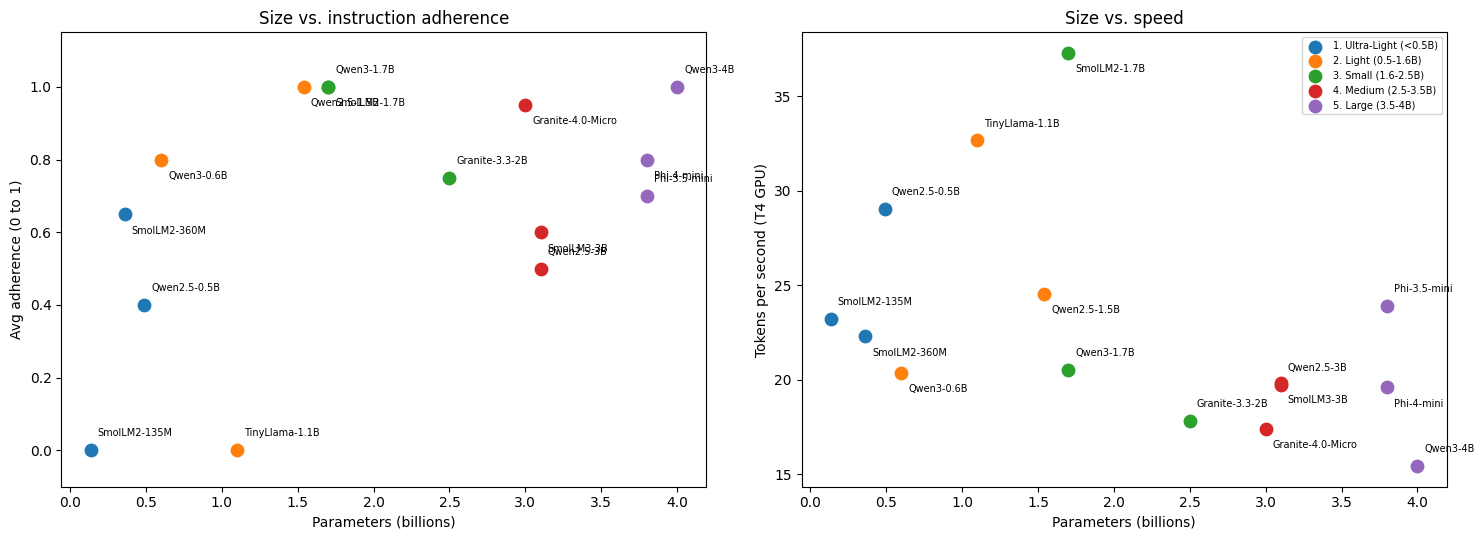

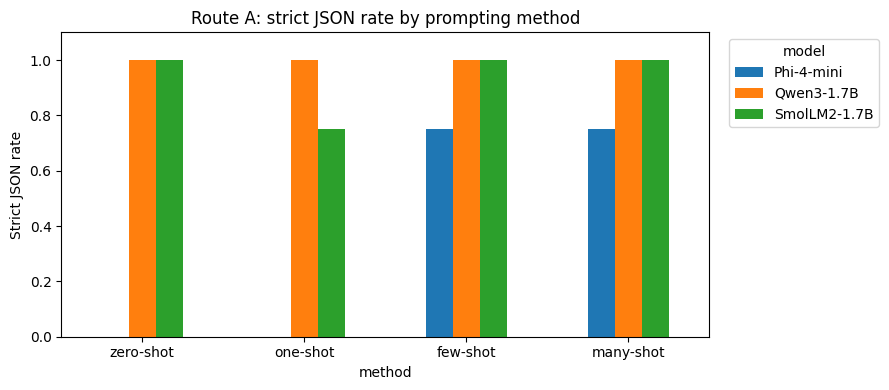

{"destination": "Yellowstone National Park", "days": [{"day": 1, "morning": "Hike the Grand Prismatic Spring trail for a short, scenic walk", "afternoon": "Visit the Yellowstone Wildlife Observatory for educational activities with kids", "evening": "Dine at the Yellowstone Restaurant on the park's edge"}, {"day": 2, "morning": "Explore the Old Faithful Volcano area and hike the Madison River Trail", "afternoon": "Watch a wildlife show at the Yellowstone Wildlife Education Center", "evening": "Enjoy a picnic at the Yellowstone Campground with a view of the park"}]}


In [ ]:
# Cell 8: Evaluation - weighted scorecard across all 15 models, plus charts
import matplotlib.pyplot as plt

# Kid-awareness on T3 (zero-shot) for all 15 models
t3 = matrix_df[matrix_df.trip == "T3"].copy()
t3["kid_aware"] = t3.output.str.lower().apply(lambda t: any(w in t for w in KID_WORDS))
score = summary_df.merge(t3[["model", "kid_aware"]], on="model")

# Normalize speed and memory to 0-1 (1 = best)
score["speed_score"] = score.avg_tok_per_sec / score.avg_tok_per_sec.max()
score["memory_score"] = score.peak_gpu_gb.min() / score.peak_gpu_gb

# Our team's criteria and weights
WEIGHTS = {"avg_adherence": 0.40, "strict_json_rate": 0.20, "kid_aware": 0.15,
           "speed_score": 0.15, "memory_score": 0.10}
score["final_score"] = sum(score[k].astype(float) * w for k, w in WEIGHTS.items()).round(3)
scorecard = score.sort_values("final_score", ascending=False)[
    ["category", "model", "params_b", "avg_adherence", "strict_json_rate", "kid_aware",
     "avg_tok_per_sec", "peak_gpu_gb", "final_score"]]
display(scorecard)

# Chart 1 and 2: size vs. quality, size vs. speed
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for cat, grp in summary_df.groupby("category"):
    axes[0].scatter(grp.params_b, grp.avg_adherence, s=80, label=cat)
    axes[1].scatter(grp.params_b, grp.avg_tok_per_sec, s=80, label=cat)
for i, (_, r) in enumerate(summary_df.sort_values(["params_b", "model"]).iterrows()):
    dy = 10 if i % 2 == 0 else -14   # alternate labels above and below the point
    axes[0].annotate(r.model, (r.params_b, r.avg_adherence), fontsize=7, xytext=(5, dy), textcoords="offset points")
    axes[1].annotate(r.model, (r.params_b, r.avg_tok_per_sec), fontsize=7, xytext=(5, dy), textcoords="offset points")
axes[0].set(xlabel="Parameters (billions)", ylabel="Avg adherence (0 to 1)", title="Size vs. instruction adherence", ylim=(-0.1, 1.15))
axes[1].set(xlabel="Parameters (billions)", ylabel="Tokens per second (T4 GPU)", title="Size vs. speed")
axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.savefig("size_tradeoffs.png", dpi=150)
plt.show()

# Chart 3: Route A, strict JSON rate by prompting method
ax = (route_a_summary.pivot(index="method", columns="model", values="strict_json_rate")
      .loc[list(SHOT_COUNTS)]
      .plot(kind="bar", figsize=(9, 4), rot=0, ylabel="Strict JSON rate", ylim=(0, 1.1),
            title="Route A: strict JSON rate by prompting method"))
ax.legend(title="model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("route_a_methods.png", dpi=150)
plt.show()

# Sanity check: did one-shot really make Qwen3-1.7B plan for the kids?
print(route_a_df[(route_a_df.model == "Qwen3-1.7B") & (route_a_df.method == "one-shot")
                 & (route_a_df.trip == "T3")].output.iloc[0])

# Part 1 Findings: Model Benchmarking for TakeOff

## 1. Model Selection
We browsed the Hugging Face Open LLM Leaderboard (archived in March 2025, so it no longer lists new models) and the Hugging Face Models Hub. We filtered for models that are:
- **Instruction-tuned**, so they follow requests rather than just continuing text
- **Ungated**, so no access approval or token is needed to download them
- **Loadable with plain `transformers`**, matching the Django integration requirement
- **From reputable organizations** (Alibaba Qwen, Hugging Face SmolLM, Microsoft Phi, IBM Granite)
- **Under ~4B parameters**, since 7B models need ~15 GB of memory and cannot run on a 16 GB laptop

We grouped them into 5 size categories with 3 models each, mixing model families within categories and including one family (SmolLM2) across three sizes for a fair size comparison.

## 2. Test Setup
- **Hardware:** Google Colab, NVIDIA T4 GPU (16 GB), float16
- **Task:** generate a day-by-day trip itinerary as strict JSON (so Django can parse and display it)
- **Inputs:** 4 fixed trips mimicking our trip-planning form: Chicago (2 days), Tokyo (3 days, low budget), Yellowstone (2 days, traveling with kids), Nashville (1 day)
- **Settings:** identical for all models (greedy decoding, max 400 new tokens, repetition penalty 1.1)

## 3. Evaluation Criteria (team-decided weights)
| Criterion | Weight | Why it matters |
|---|---|---|
| Instruction adherence (correct days, all slots filled, right destination) | 40% | A wrong plan makes the feature useless |
| Strict JSON (no extra text) | 20% | Django can only display output that parses cleanly |
| Kid-awareness on the Yellowstone trip | 15% | Tests whether the model reads hidden user constraints |
| Speed (tokens/sec) | 15% | Users will not wait long for an itinerary |
| Memory use | 10% | Must run on a laptop and keep server costs low |

## 4. Zero-Shot Results (Top 5)
| Rank | Model | Size | Adherence | Strict JSON | Kid-aware | Speed (tok/s) | Memory (GB) | Score |
|---|---|---|---|---|---|---|---|---|
| 1 | Qwen3-4B | 4.0B | 1.00 | 1.00 | Yes | 15.4 | 8.2 | 0.816 |
| 2 | SmolLM2-1.7B | 1.7B | 1.00 | 1.00 | No | 37.3 | 3.5 | 0.758 |
| 3 | Granite-4.0-Micro | 3.0B | 0.95 | 0.75 | Yes | 17.4 | 6.9 | 0.754 |
| 4 | Qwen2.5-1.5B | 1.5B | 1.00 | 1.00 | No | 24.6 | 3.1 | 0.708 |
| 5 | Qwen3-1.7B | 1.7B | 1.00 | 1.00 | No | 20.5 | 3.5 | 0.691 |

**Key observations:**
- Models under 0.5B (and TinyLlama-1.1B) could not follow the JSON format at all.
- **~1.5B to 1.7B is the sweet spot.** Quality did not keep rising with size; several 3B to 4B models (Phi-3.5-mini, Phi-4-mini, Qwen2.5-3B, SmolLM3-3B) scored lower than the 1.7B models.
- Speed depends on architecture, not just size: SmolLM2-1.7B was faster than models a tenth of its size.
- Several models (Phi-4-mini, SmolLM3-3B, Qwen3-0.6B) produced correct JSON but wrapped it in markdown code fences, failing strict parsing.

## 5. Route A: Prompt Engineering
We tested zero-shot, one-shot, few-shot (3 examples), and many-shot (8 examples) on Qwen3-1.7B, SmolLM2-1.7B, and Phi-4-mini.

| Model | Zero-shot | One-shot | Few-shot | Many-shot |
|---|---|---|---|---|
| SmolLM2-1.7B (strict JSON / kid-aware) | 4/4 / No | 3/4 / Yes | 4/4 / Yes | 4/4 / No |
| Qwen3-1.7B (strict JSON / kid-aware) | 4/4 / No | 4/4 / Yes | 4/4 / No | 4/4 / No |
| Phi-4-mini (strict JSON / kid-aware) | 0/4 / Yes | 0/4 / Yes | 3/4 / Yes | 3/4 / Yes |

**Findings:**
- **Few-shot was the most reliable method for structure.** It fixed Phi-4-mini's code-fence habit (0/4 to 3/4), which one example could not do.
- **Relevant examples matter more than the number of examples.** The kids example made models plan for children in one-shot and few-shot, but in many-shot it was buried among 7 other examples and the effect faded.
- Prompt length grew ~10x (≈110 to ≈1,100 tokens) with little change in GPU generation time, but with a paid API, input tokens cost money, so many-shot would be ~10x more expensive per request.

## 6. Final Decision
**Qwen3-4B scored highest overall, but we chose SmolLM2-1.7B with few-shot prompting for deployment.** With few-shot examples it matches Qwen3-4B on format and constraint-awareness, while being ~5x faster (~3 sec vs ~17 sec per itinerary on the T4) and using less than half the memory (3.5 GB vs 8.2 GB). This keeps the Django app responsive on a laptop and makes the instructor's local test fast. Qwen3-4B remains our quality benchmark.

## 7. Limitations
- **Our grader checks format, not factual accuracy.** Small models invent plausible place names (for example "Yellowstone Wildlife Observatory," which does not exist). Our Django integration needs a guardrail for this, such as validating output or using an external API to verify places.
- **Kid-awareness is a keyword check** (mentions of kids, children, or family), so it is a rough signal, not proof of good family planning.
- Only 4 test prompts and greedy decoding were used, so results show clear trends but are not a full benchmark.